In [1]:
import pandas as pd
import os

def load_physionet_data(path):
    all_data = []
    for file in os.listdir(path):
        if file.endswith(".psv"):
            patient_id = file.replace(".psv", "")
            df = pd.read_csv(os.path.join(path, file), sep='|')
            df["Patient_ID"] = patient_id
            all_data.append(df)
    return pd.concat(all_data, ignore_index=True)

train_A_path = r"C:\Users\gulsh\OneDrive\Desktop\research projects\sepsis prediction\training\training_setA"
train_B_path = r"C:\Users\gulsh\OneDrive\Desktop\research projects\sepsis prediction\training\training_setB"

df_A = load_physionet_data(train_A_path)
df_B = load_physionet_data(train_B_path)

df = pd.concat([df_A, df_B], ignore_index=True)
print(df.shape)
df.head()


(1552210, 42)


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0,p000001
1,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0,p000001
2,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0,p000001
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0,p000001
4,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0,p000001


In [2]:
# Patient-level sepsis distribution
patient_labels = df.groupby('Patient_ID')['SepsisLabel'].last()

num_sepsis = (patient_labels == 1).sum()
num_non_sepsis = (patient_labels == 0).sum()
total_patients = patient_labels.shape[0]

print("📊 Patient-Level Sepsis Distribution")
print("=" * 40)
print(f"Total patients       : {total_patients}")
print(f"Sepsis patients      : {num_sepsis}")
print(f"Non-sepsis patients  : {num_non_sepsis}")
print(f"Sepsis ratio         : {num_sepsis / total_patients:.4f}")


📊 Patient-Level Sepsis Distribution
Total patients       : 40336
Sepsis patients      : 2932
Non-sepsis patients  : 37404
Sepsis ratio         : 0.0727


In [11]:
df.info()
df.isna().sum().sort_values(ascending=False).head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1552210 entries, 0 to 1552209
Data columns (total 42 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   HR                1398811 non-null  float64
 1   O2Sat             1349474 non-null  float64
 2   Temp              525226 non-null   float64
 3   SBP               1325945 non-null  float64
 4   MAP               1358940 non-null  float64
 5   DBP               1065656 non-null  float64
 6   Resp              1313875 non-null  float64
 7   EtCO2             57636 non-null    float64
 8   BaseExcess        84145 non-null    float64
 9   HCO3              65028 non-null    float64
 10  FiO2              129365 non-null   float64
 11  pH                107573 non-null   float64
 12  PaCO2             86301 non-null    float64
 13  SaO2              53561 non-null    float64
 14  AST               25183 non-null    float64
 15  BUN               106568 non-null   float64
 16  

Bilirubin_direct    1549220
Fibrinogen          1541968
TroponinI           1537429
Bilirubin_total     1529069
Alkalinephos        1527269
AST                 1527027
Lactate             1510764
PTT                 1506511
SaO2                1498649
EtCO2               1494574
dtype: int64

In [12]:
df.describe()

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
count,1.398811e+06,1.349474e+06,525226.000000,1.325945e+06,1.358940e+06,1.065656e+06,1.313875e+06,57636.000000,84145.000000,65028.000000,...,99447.000000,10242.000000,92209.000000,1.552210e+06,1.552210e+06,940250.000000,940250.000000,1.552202e+06,1.552210e+06,1.552210e+06
mean,8.458144e+01,9.719395e+01,36.977228,1.237505e+02,8.240010e+01,6.383056e+01,1.872650e+01,32.957657,-0.689919,24.075481,...,11.446405,287.385706,196.013911,6.200947e+01,5.592690e-01,0.496571,0.503429,-5.612512e+01,2.699499e+01,1.798468e-02
std,1.732524e+01,2.936924e+00,0.770014,2.323156e+01,1.634175e+01,1.395601e+01,5.098194e+00,7.951662,4.294297,4.376504,...,7.731013,153.002908,103.635366,1.638622e+01,4.964749e-01,0.499989,0.499989,1.622569e+02,2.900542e+01,1.328956e-01
min,2.000000e+01,2.000000e+01,20.900000,2.000000e+01,2.000000e+01,2.000000e+01,1.000000e+00,10.000000,-32.000000,0.000000,...,0.100000,34.000000,1.000000,1.400000e+01,0.000000e+00,0.000000,0.000000,-5.366860e+03,1.000000e+00,0.000000e+00
25%,7.200000e+01,9.600000e+01,36.500000,1.070000e+02,7.100000e+01,5.400000e+01,1.500000e+01,28.000000,-3.000000,22.000000,...,7.600000,184.000000,126.000000,5.168000e+01,0.000000e+00,0.000000,0.000000,-4.705000e+01,1.100000e+01,0.000000e+00
50%,8.350000e+01,9.800000e+01,37.000000,1.210000e+02,8.000000e+01,6.200000e+01,1.800000e+01,33.000000,0.000000,24.000000,...,10.300000,250.000000,181.000000,6.400000e+01,1.000000e+00,0.000000,1.000000,-6.030000e+00,2.100000e+01,0.000000e+00
75%,9.550000e+01,9.950000e+01,37.500000,1.380000e+02,9.200000e+01,7.200000e+01,2.150000e+01,38.000000,1.000000,26.800000,...,13.800000,349.000000,244.000000,7.400000e+01,1.000000e+00,1.000000,1.000000,-4.000000e-02,3.400000e+01,0.000000e+00
max,2.800000e+02,1.000000e+02,50.000000,3.000000e+02,3.000000e+02,3.000000e+02,1.000000e+02,100.000000,100.000000,55.000000,...,440.000000,1760.000000,2322.000000,1.000000e+02,1.000000e+00,1.000000,1.000000,2.399000e+01,3.360000e+02,1.000000e+00


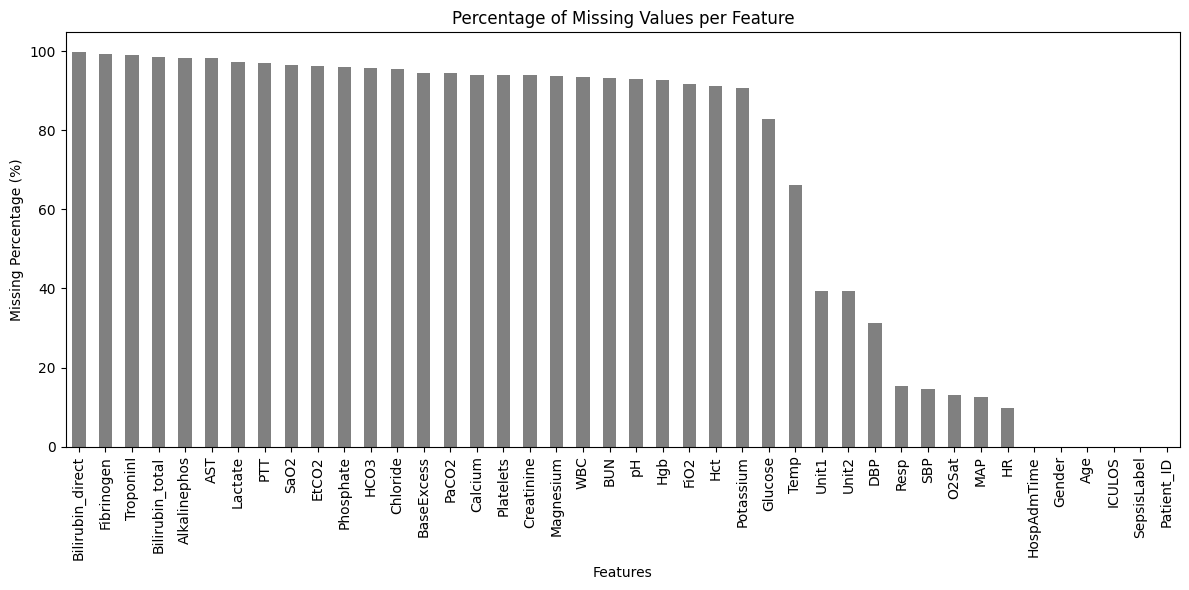

Bilirubin_direct    99.807371
Fibrinogen          99.340167
TroponinI           99.047745
Bilirubin_total     98.509158
Alkalinephos        98.393194
AST                 98.377604
Lactate             97.329872
PTT                 97.055875
SaO2                96.549372
EtCO2               96.286843
dtype: float64

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming df is already loaded as per previous steps
# Calculate percentage of missing values per column
missing_percent = df.isnull().mean() * 100
missing_percent = missing_percent.sort_values(ascending=False)

# Plot missing value percentages
plt.figure(figsize=(12, 6))
missing_percent.plot(kind='bar', color='gray')
plt.title('Percentage of Missing Values per Feature')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Features')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display top 10 features with the most missing data
missing_percent.head(10)


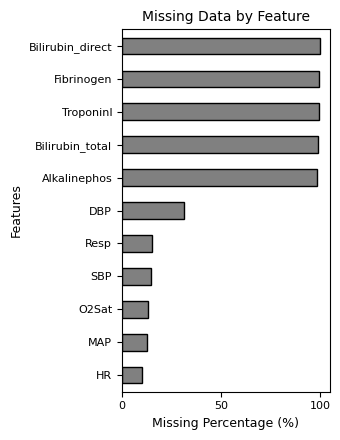

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate percentage of missing values for all columns
missing_percent = df.isnull().mean() * 100

# Define the specific features you want to highlight
selected_features = [
    'Bilirubin_direct', 'Fibrinogen', 'TroponinI', 'Bilirubin_total', 
    'Alkalinephos', 'DBP', 'Resp', 'SBP', 'O2Sat', 'MAP', 'HR'
]

# Filter the series and sort ascending 
# (For horizontal bar charts, ascending puts the largest value at the top)
missing_filtered = missing_percent[selected_features].sort_values(ascending=True)

# Set figure size to a standard single-column width (~3.5 inches) and a vertical height
plt.figure(figsize=(3.5, 4.5))

# Use horizontal bars to create a clean, vertical list of features
missing_filtered.plot(kind='barh', color='gray', edgecolor='black')

# Format title and labels with smaller font sizes suitable for a paper column
plt.title('Missing Data by Feature', fontsize=10)
plt.xlabel('Missing Percentage (%)', fontsize=9)
plt.ylabel('Features', fontsize=9)

# Scale tick fonts down so they don't dominate the narrow plot
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

# Ensure the labels are not clipped when saving the figure
plt.tight_layout()
plt.show()

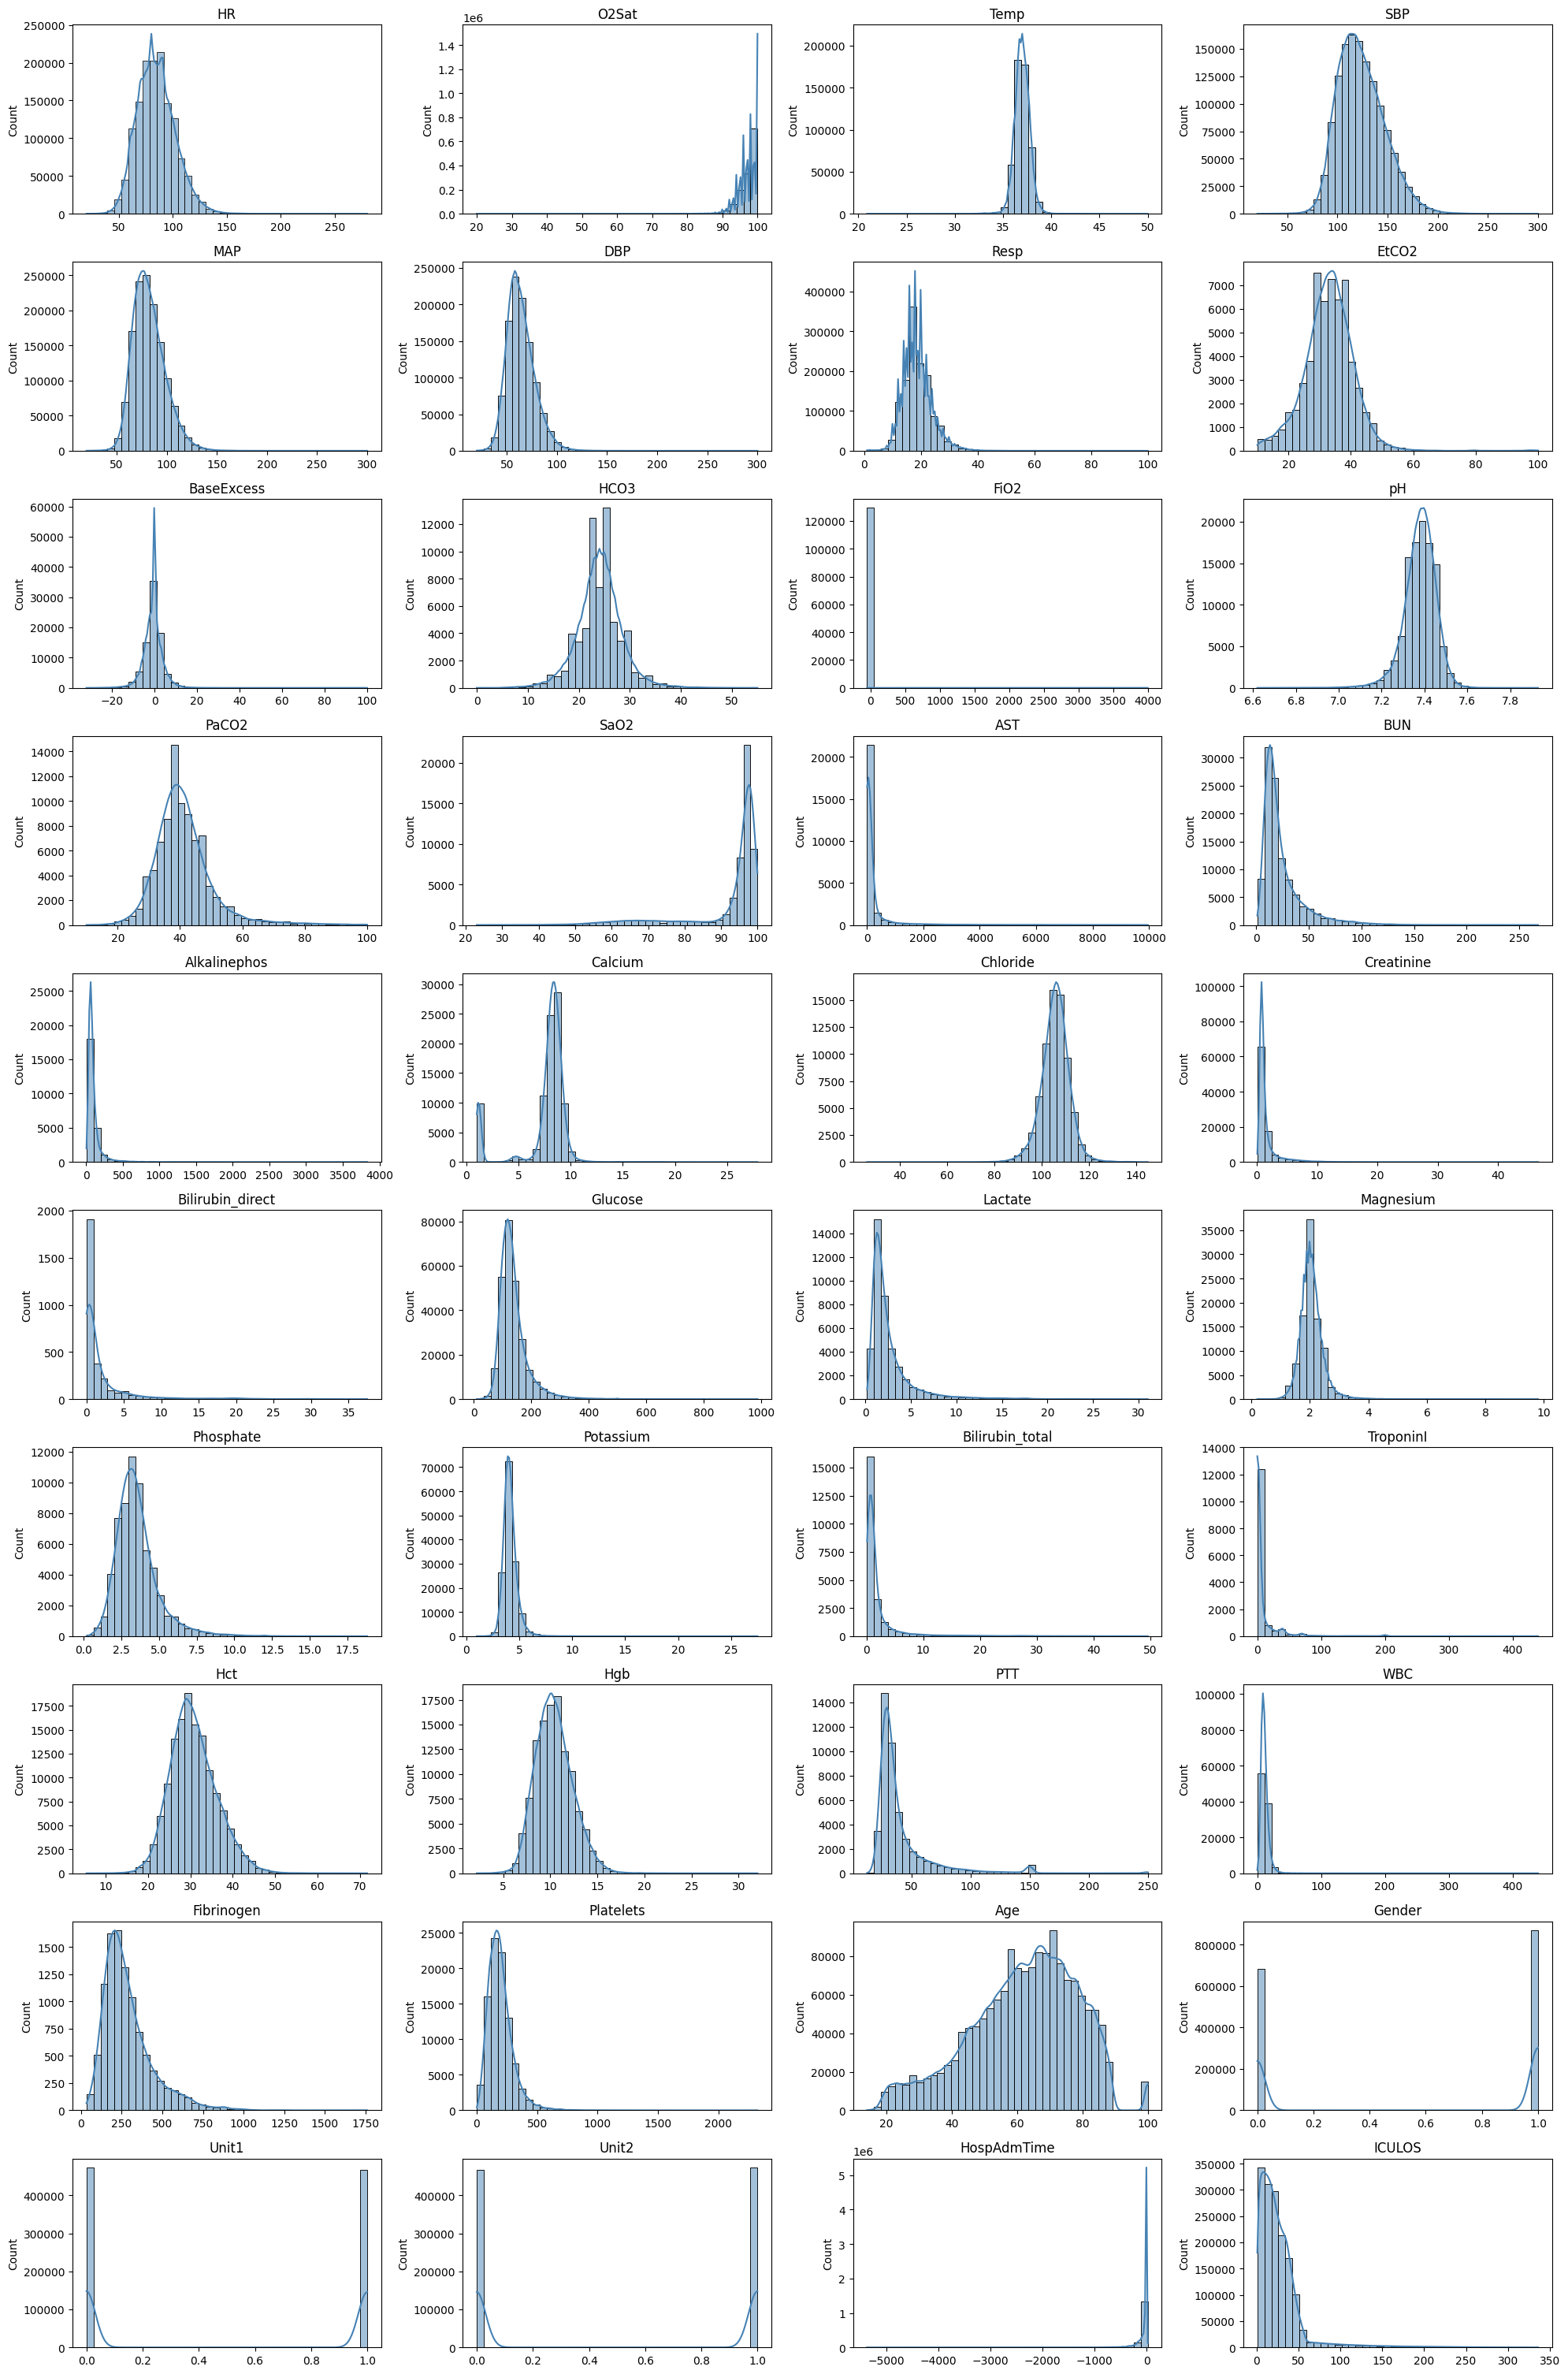

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df is already loaded and cleaned
# Identify numerical columns (excluding ID and label)
num_features = [col for col in df.columns if col not in ["Patient_ID", "SepsisLabel"]]


# Plot histograms for each vital/lab feature
n_cols = 4
n_rows = len(num_features) // n_cols + 1
plt.figure(figsize=(20, n_rows * 3))

for i, col in enumerate(num_features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(df[col], kde=True, color='steelblue', bins=40)
    plt.title(col)
    plt.xlabel("")
    plt.tight_layout()

plt.show()

C:\Users\gulsh\AppData\Local\Temp\ipykernel_15884\2139612778.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="SepsisLabel", y=col, data=df_sample, palette="muted", inner="quart")
C:\Users\gulsh\AppData\Local\Temp\ipykernel_15884\2139612778.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="SepsisLabel", y=col, data=df_sample, palette="muted", inner="quart")
C:\Users\gulsh\AppData\Local\Temp\ipykernel_15884\2139612778.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="SepsisLabel", y=col, data=df_sample, palette="mut

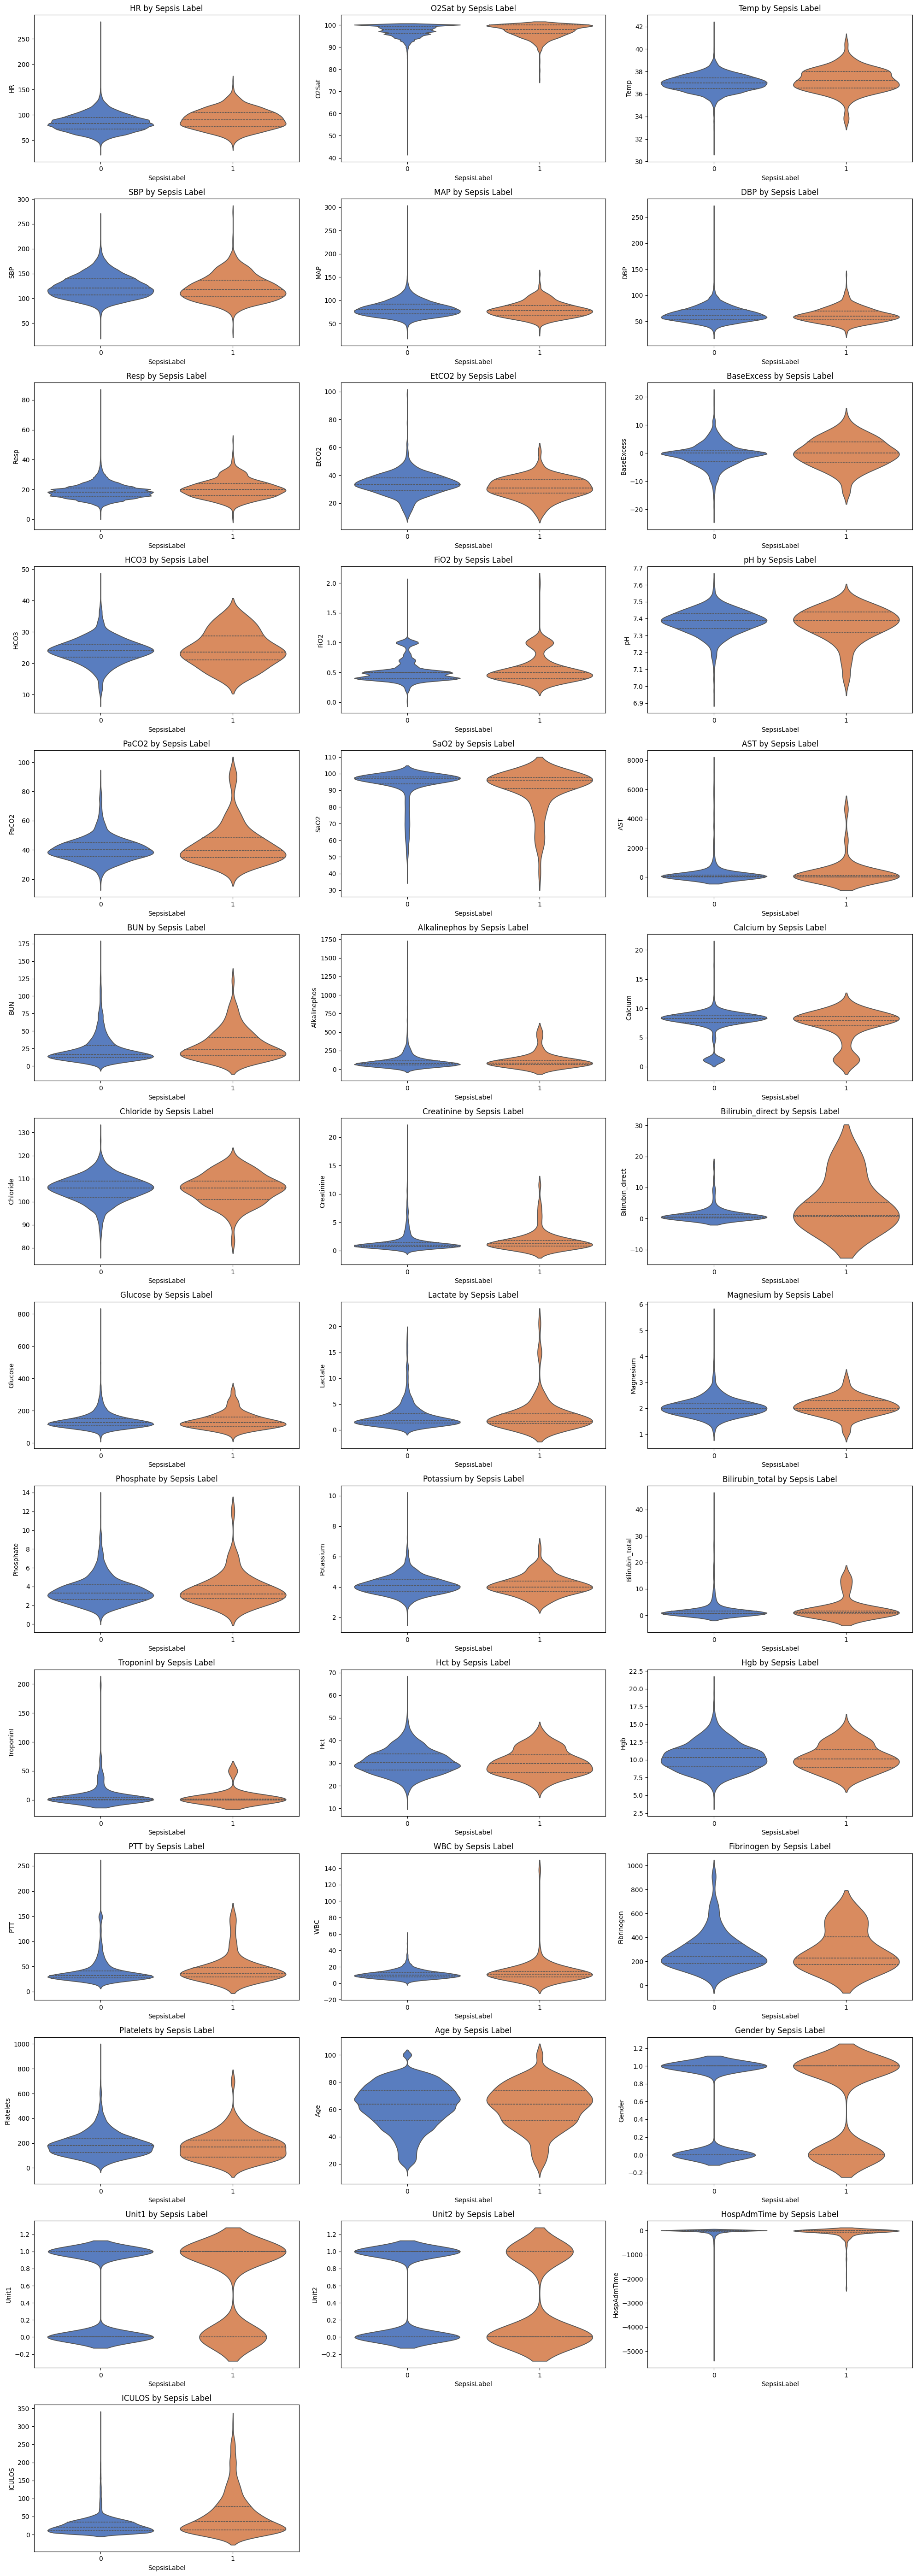

In [15]:
# Sample a subset for faster plotting (optional)
df_sample = df.sample(n=50000, random_state=42) if len(df) > 50000 else df

n_cols = 3
n_rows = len(num_features) // n_cols + 1
plt.figure(figsize=(20, n_rows * 4))

for i, col in enumerate(num_features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.violinplot(x="SepsisLabel", y=col, data=df_sample, palette="muted", inner="quart")
    plt.title(f"{col} by Sepsis Label")
    plt.tight_layout()

plt.show()


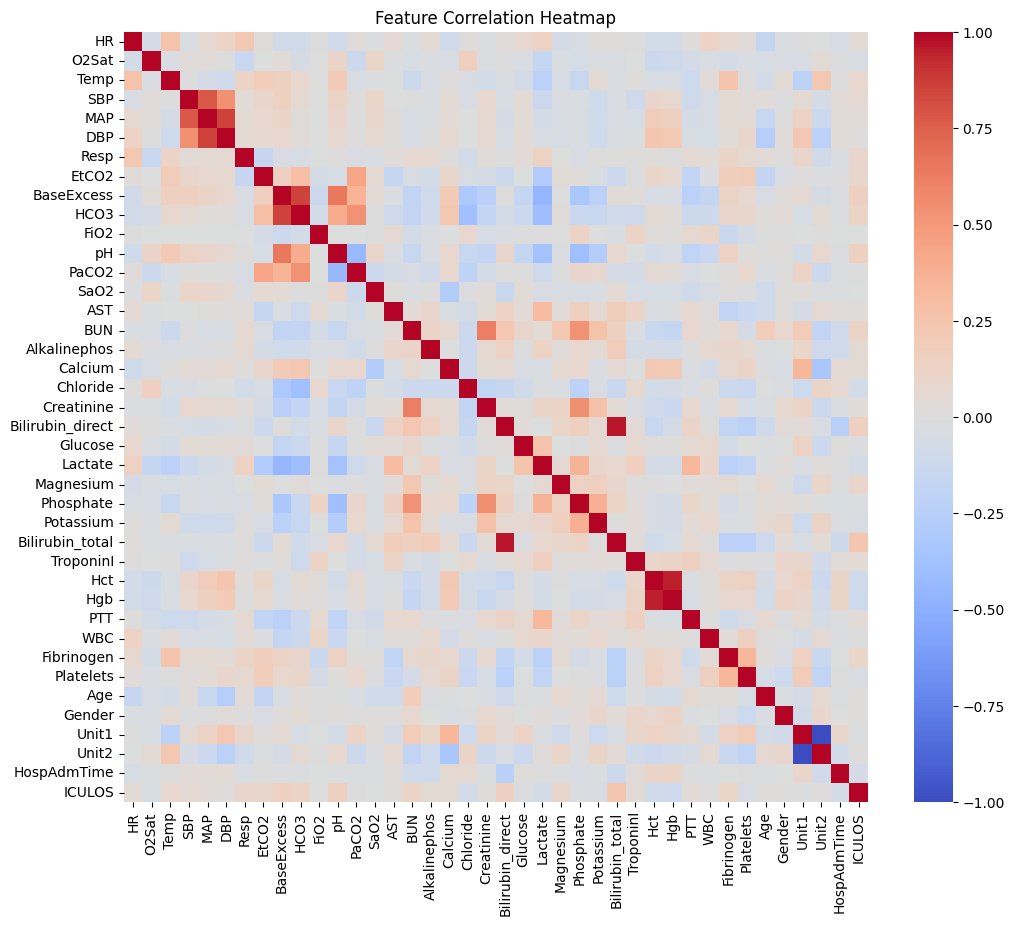

In [16]:
# Compute correlation matrix for numeric features
corr_matrix = df[num_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()


🩸 Septic Patients (SepsisLabel = 1)


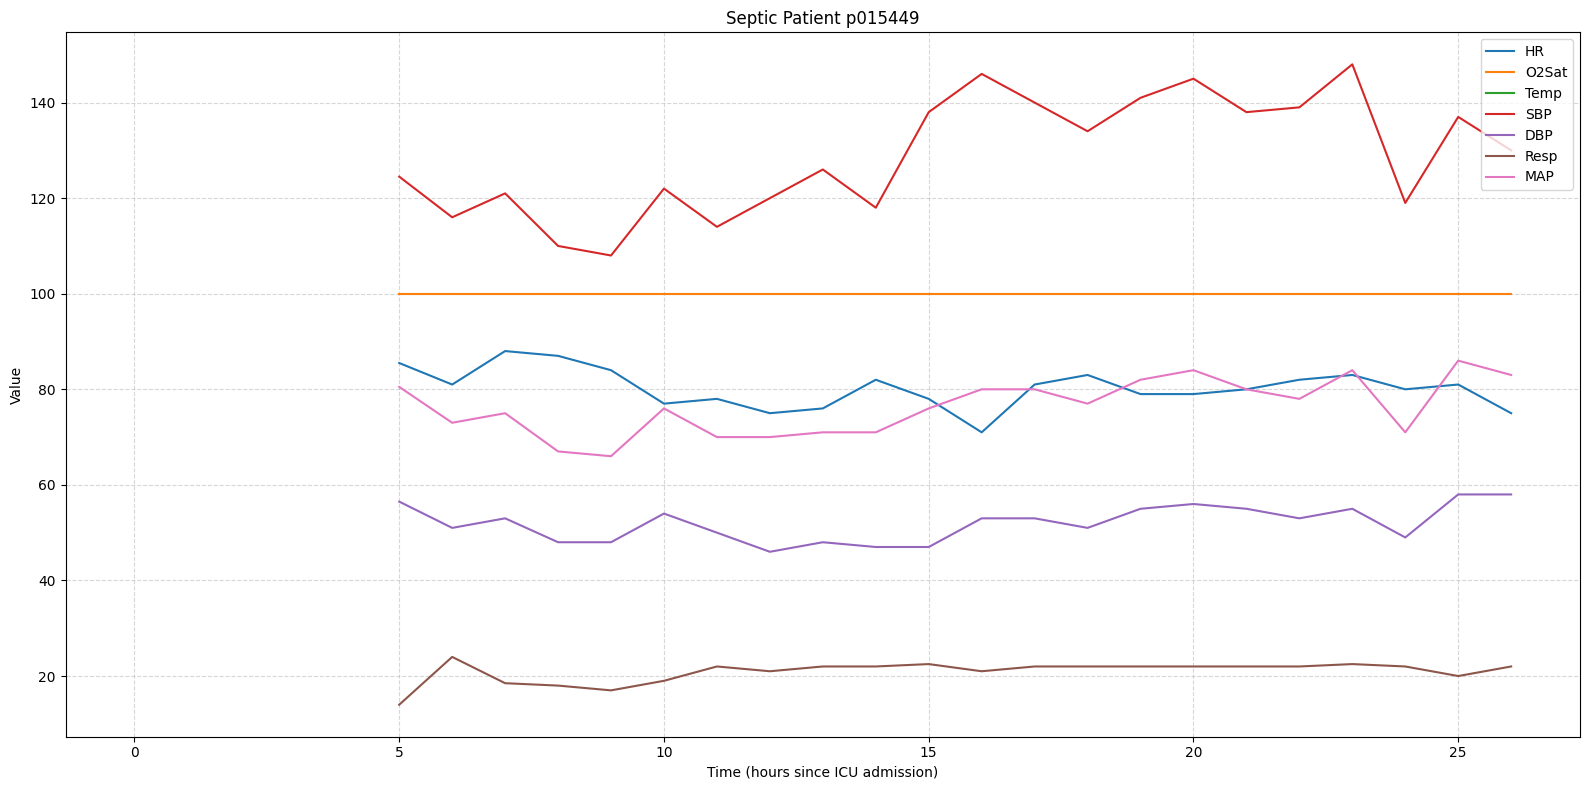

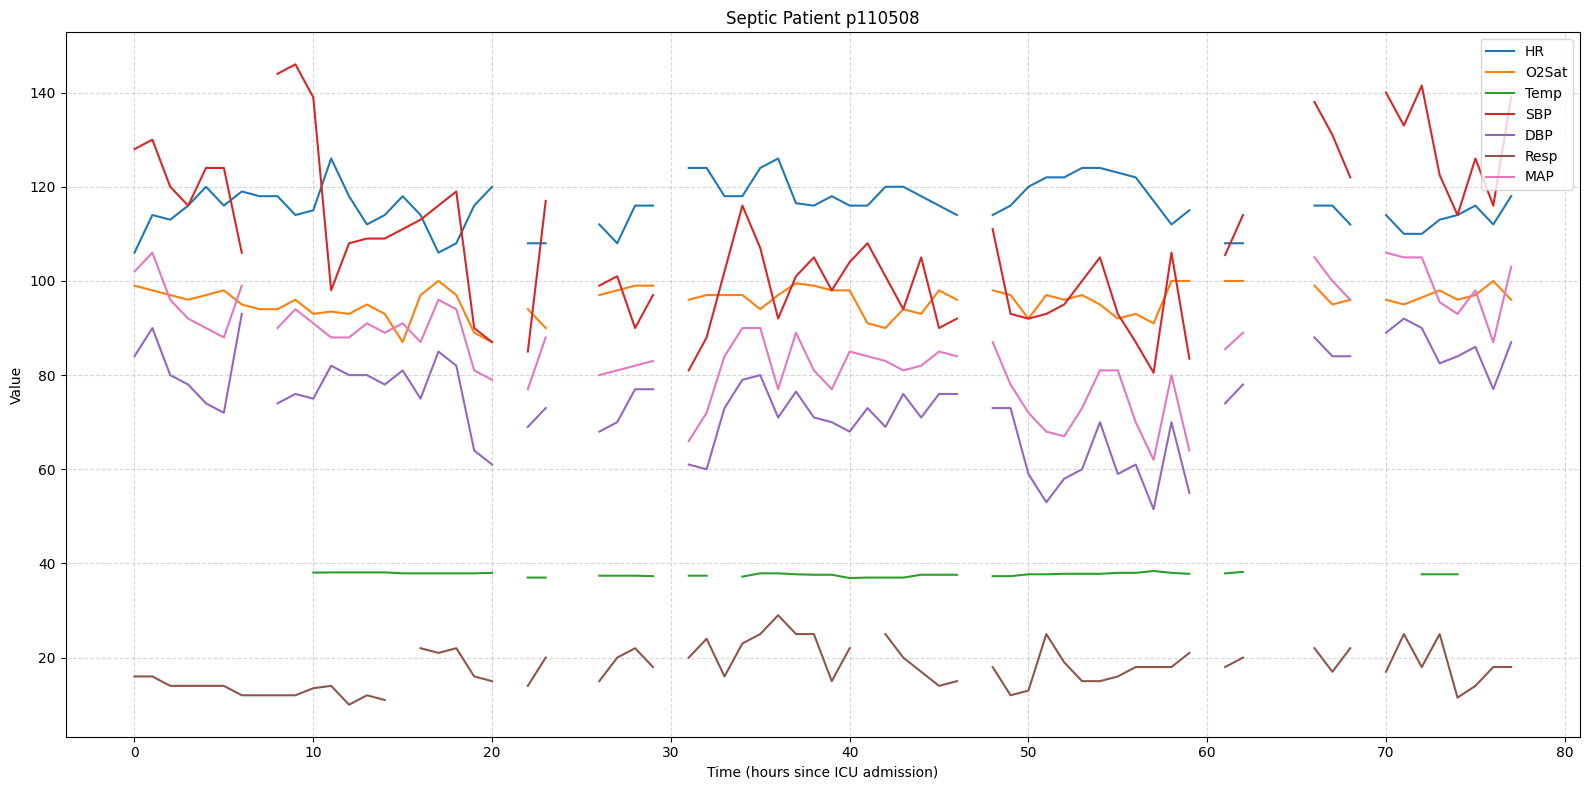

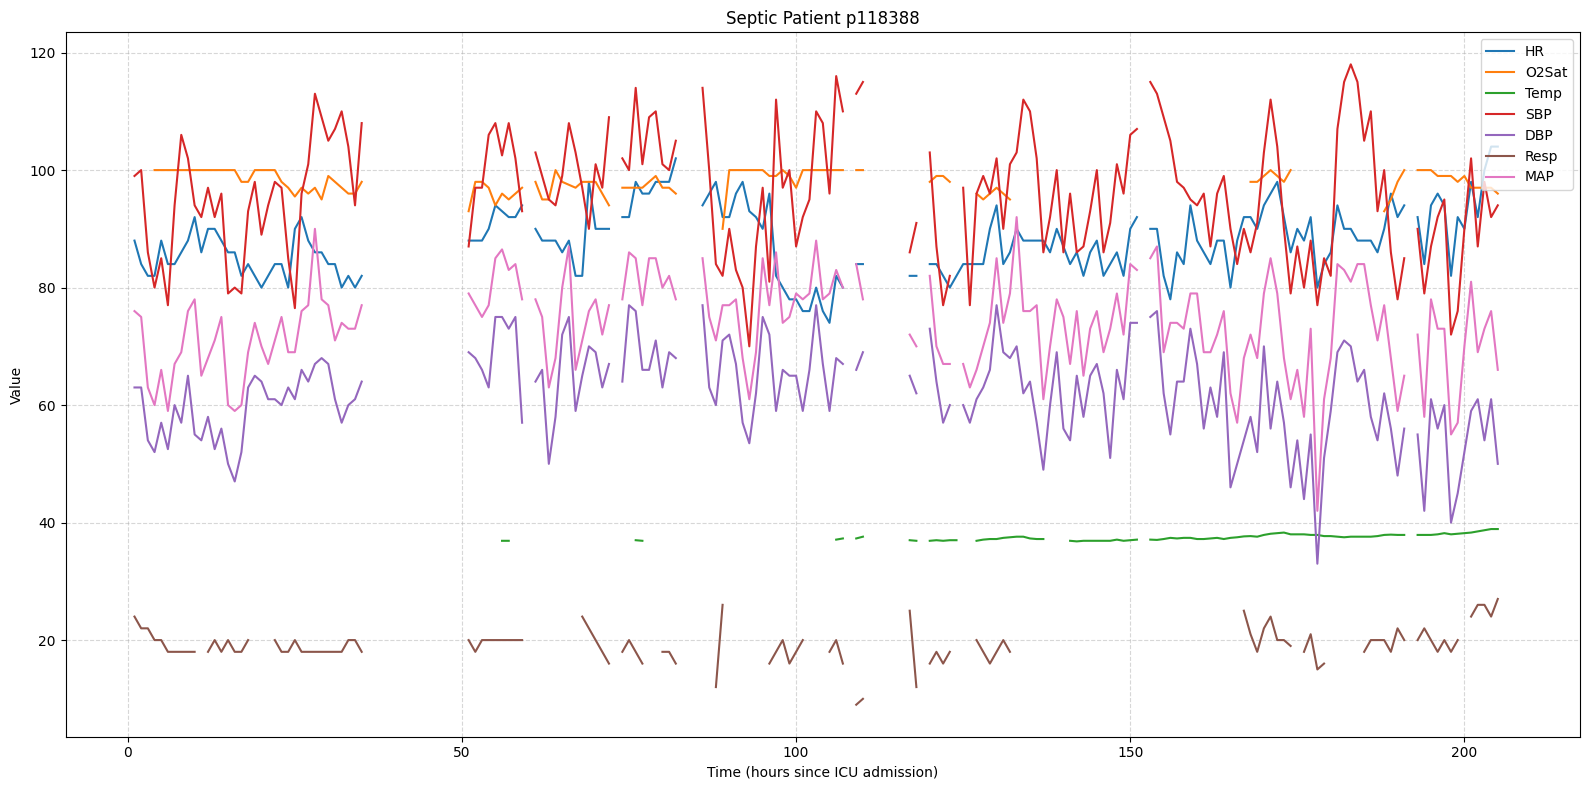

🩺 Non-Septic Patients (SepsisLabel = 0)


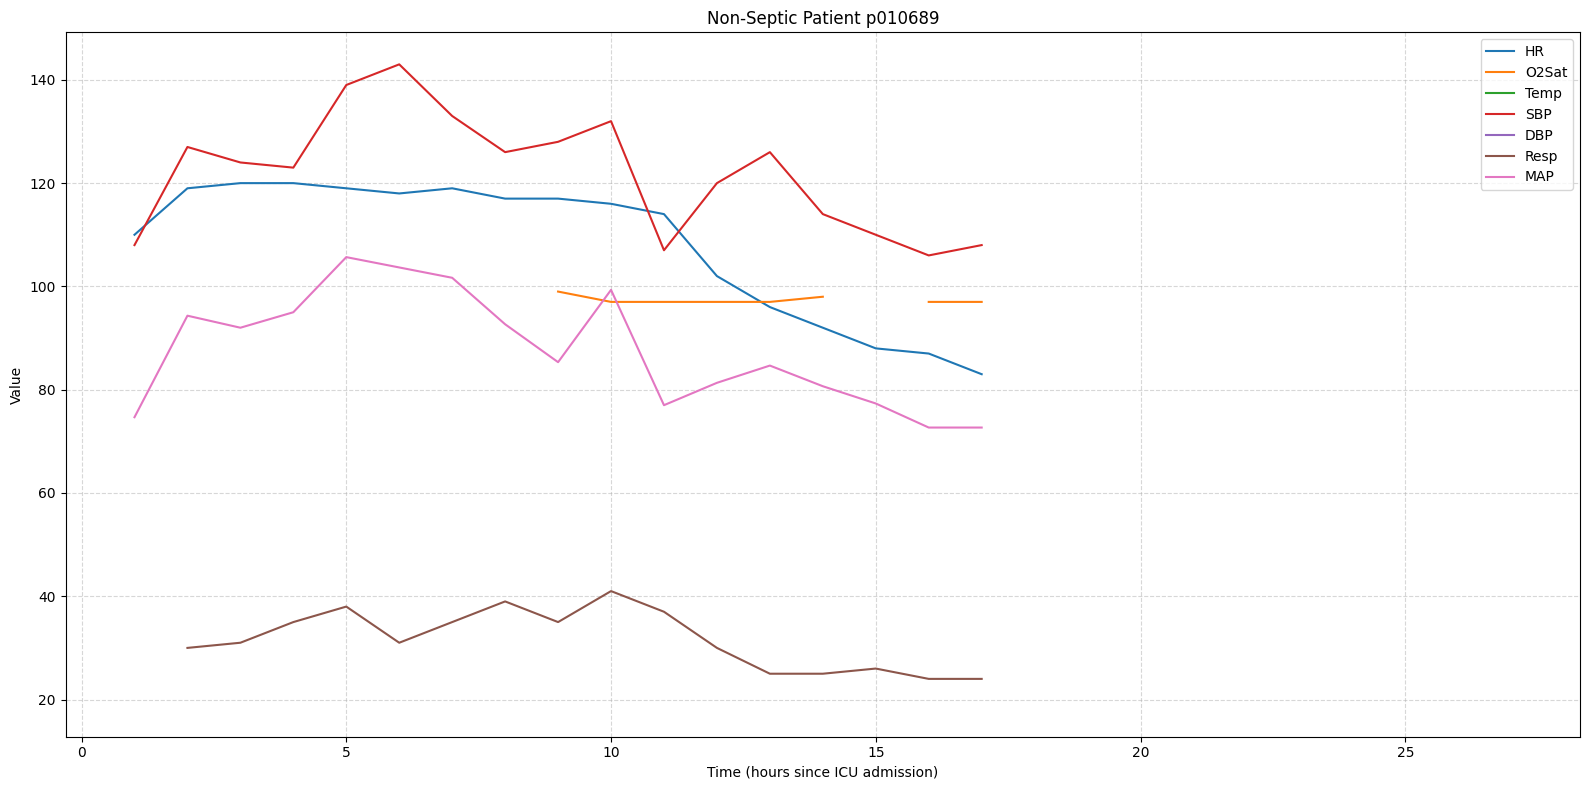

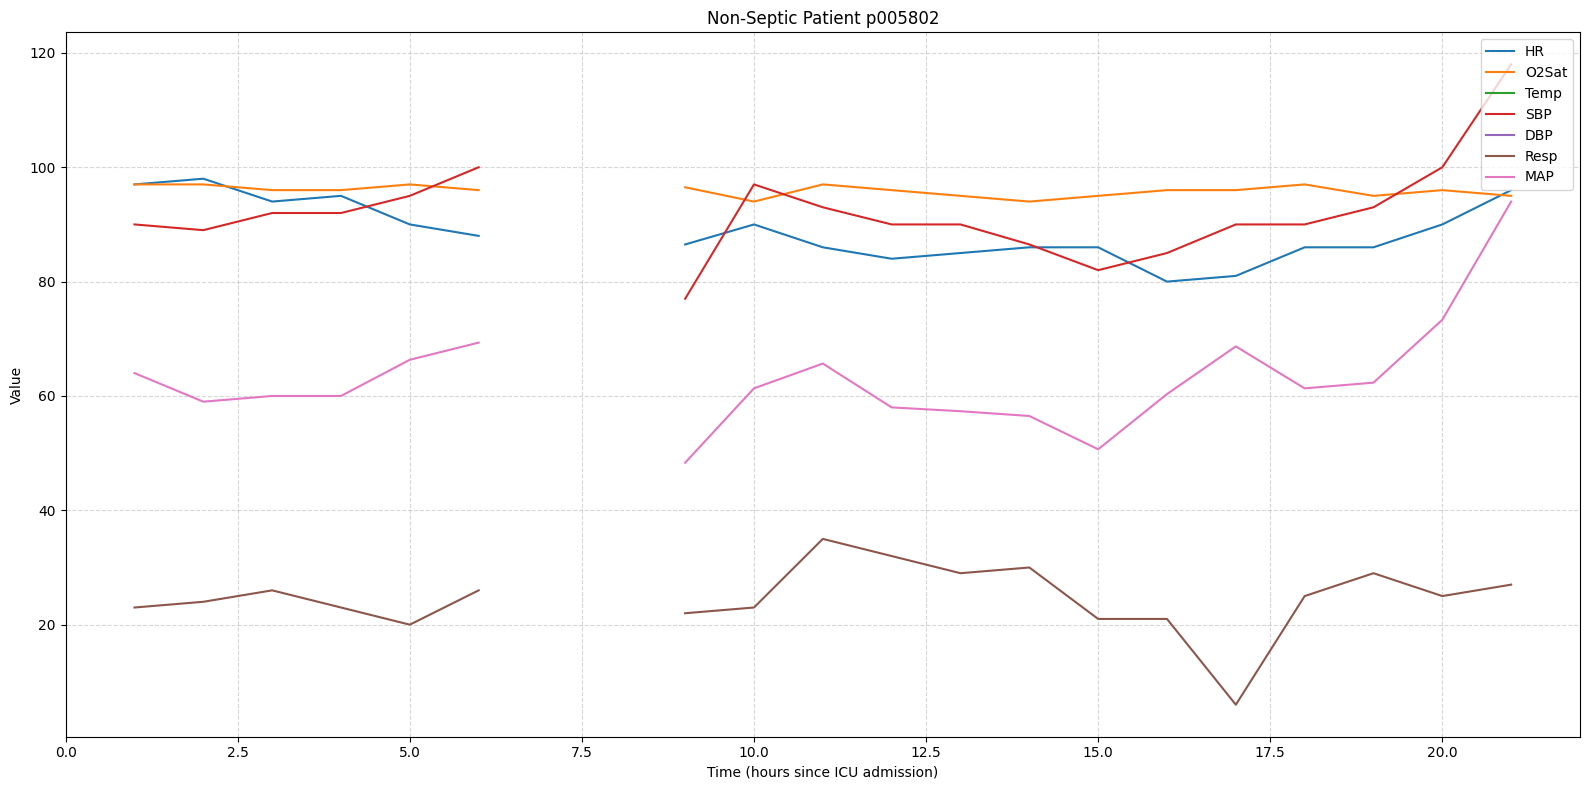

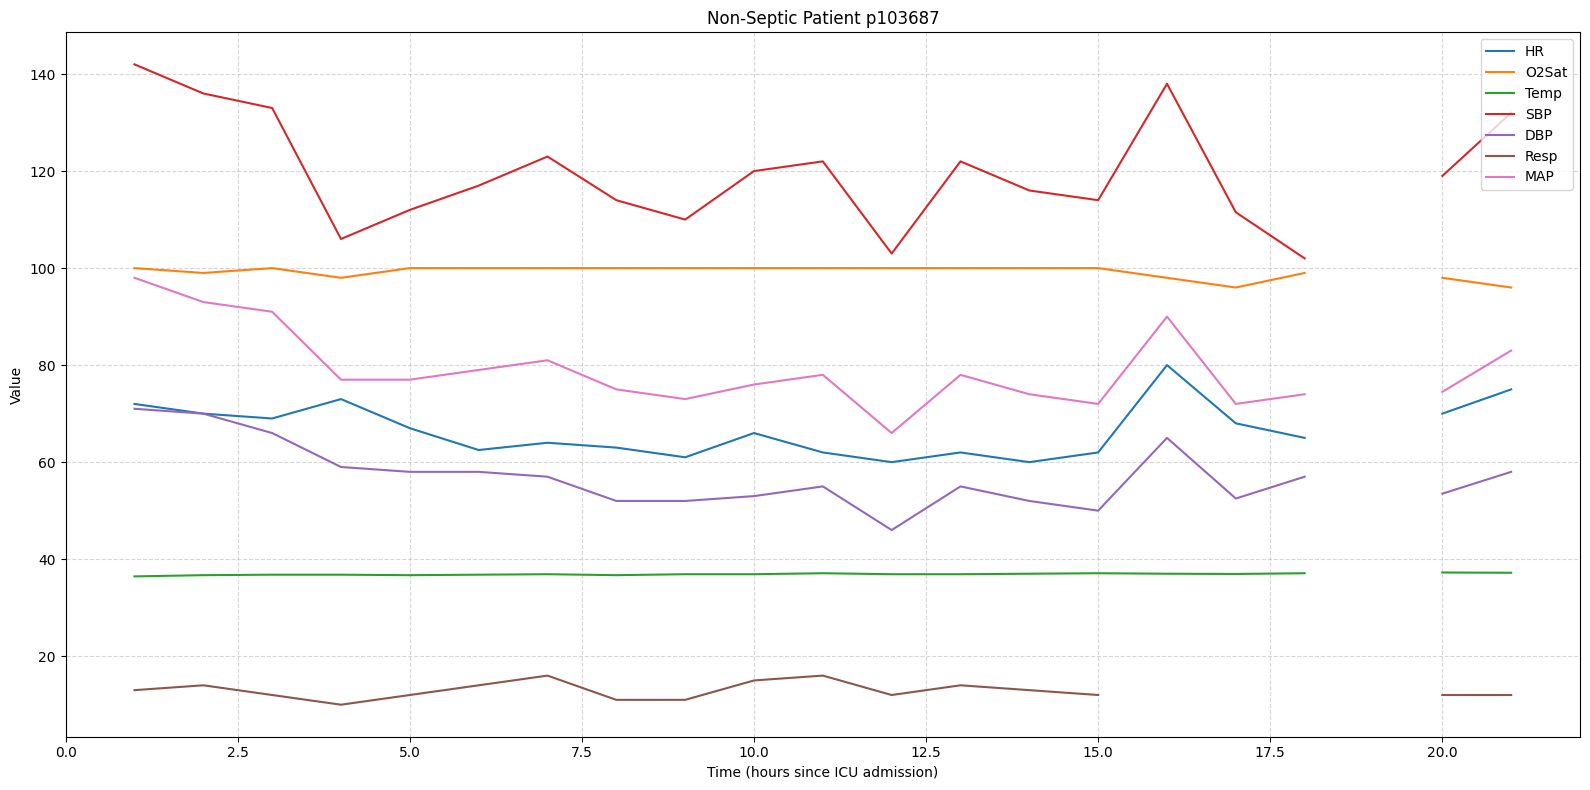

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure your dataset is loaded
# df = pd.read_parquet("your_preprocessed_data.parquet")

# Define key vital signs for temporal visualization
vital_signs = [
    "HR", "O2Sat", "Temp", "SBP", "DBP", "Resp", "MAP"
]  # You can modify this list based on dataset columns

#  Identify septic and non-septic patients 
septic_patients = df[df["SepsisLabel"] == 1]["Patient_ID"].unique()
non_septic_patients = df[df["SepsisLabel"] == 0]["Patient_ID"].unique()

# Randomly pick a few patients for each group
import numpy as np
np.random.seed(42)
septic_sample = np.random.choice(septic_patients, size=3, replace=False)
non_septic_sample = np.random.choice(non_septic_patients, size=3, replace=False)

#  Define plotting function for patient trajectories 
def plot_patient_trajectories(patient_ids, title_prefix):
    for pid in patient_ids:
        patient_df = df[df["Patient_ID"] == pid]
        patient_df = patient_df.reset_index(drop=True)
        time = patient_df.index  # assuming each row = 1 hour (as per dataset)
        
        plt.figure(figsize=(16, 8))
        for col in vital_signs:
            if col in patient_df.columns:
                plt.plot(time, patient_df[col], label=col)
        
        plt.title(f"{title_prefix} Patient {pid}")
        plt.xlabel("Time (hours since ICU admission)")
        plt.ylabel("Value")
        plt.legend(loc="upper right")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

#  Plot trajectories for septic and non-septic patients 
print("🩸 Septic Patients (SepsisLabel = 1)")
plot_patient_trajectories(septic_sample, "Septic")

print("🩺 Non-Septic Patients (SepsisLabel = 0)")
plot_patient_trajectories(non_septic_sample, "Non-Septic")


In [ ]:
import numpy as np

#  1. Identify Sepsis vs Non-Sepsis Patients 
patient_summary = df.groupby('Patient_ID')['SepsisLabel'].max()
sepsis_pids = patient_summary[patient_summary == 1].index.tolist()
non_sepsis_pids = patient_summary[patient_summary == 0].index.tolist()

print(f"Total Sepsis Patients: {len(sepsis_pids)}")
print(f"Total Non-Sepsis Patients: {len(non_sepsis_pids)}")

#  2. Filter for 'Valuable' Non-Sepsis Patients 
# We want non-sepsis patients with longer stays (e.g., at least 10 hours) 
# so the model learns from actual trajectories, not just 2-3 rows.
stay_lengths = df.groupby('Patient_ID').size()
valuable_non_sepsis_pids = stay_lengths[
    (stay_lengths.index.isin(non_sepsis_pids)) & (stay_lengths >= 10)
].index.tolist()

print(f"Valuable Non-Sepsis Patients (Stay >= 10h): {len(valuable_non_sepsis_pids)}")

#  3. Randomly Sample to Balance 
np.random.seed(42) # For reproducibility
sampled_non_sepsis_pids = np.random.choice(
    valuable_non_sepsis_pids, size=len(sepsis_pids), replace=False
).tolist()

#  4. Create the Balanced Dataset 
selected_pids = sepsis_pids + sampled_non_sepsis_pids
df_balanced = df[df['Patient_ID'].isin(selected_pids)].copy()

print(f"\nFinal Balanced Dataset Shape: {df_balanced.shape}")
print(f"Number of Patients: {df_balanced['Patient_ID'].nunique()} (50/50 Split)")

Total Sepsis Patients: 2932
Total Non-Sepsis Patients: 37404
Valuable Non-Sepsis Patients (Stay >= 10h): 37208

Final Balanced Dataset Shape: (280202, 42)
Number of Patients: 5864 (50/50 Split)


In [4]:
def create_early_warning_labels(df, lead_time=6):
    df = df.sort_values(['Patient_ID', 'ICULOS'])
    
    # 1. Find the first hour of sepsis for every patient
    # If they never have sepsis, this will be infinity
    first_sepsis_hour = df[df['SepsisLabel'] == 1].groupby('Patient_ID')['ICULOS'].min()
    df['first_sepsis_hour'] = df['Patient_ID'].map(first_sepsis_hour).fillna(np.inf)

    # 2. Create the 'target'
    # Target is 1 if the current hour is within 'lead_time' of the first_sepsis_hour
    # Formula: (first_sepsis_hour - lead_time) <= current_hour < first_sepsis_hour
    df['target'] = 0
    df.loc[
        (df['ICULOS'] >= (df['first_sepsis_hour'] - lead_time)) & 
        (df['ICULOS'] < df['first_sepsis_hour']), 
        'target'
    ] = 1

    # 3. Clean up: Remove rows where the patient IS ALREADY septic (SepsisLabel == 1)
    # We want to predict the onset, so we stop the clock once sepsis is actually detected.
    df_final = df[df['SepsisLabel'] == 0].copy()
    
    # Drop helper column
    df_final = df_final.drop(columns=['first_sepsis_hour'])
    
    return df_final

df_task = create_early_warning_labels(df_balanced, lead_time=6)

print(f"New Task Dataset Shape: {df_task.shape}")
print("Target Distribution (at hour level):")
print(df_task['target'].value_counts(normalize=True))

New Task Dataset Shape: (252286, 43)
Target Distribution (at hour level):
target
0    0.944194
1    0.055806
Name: proportion, dtype: float64


--- Hour-Level Target Distribution ---
Healthy Hours (0): 238207 (94.42%)
Pre-Sepsis Hours (1): 14079 (5.58%)
----------------------------------------
Verification for Sepsis Patient p000009:
Total hours remaining before onset: 248
Last 8 rows of their trajectory (Target should be 1 for the final 6):
     ICULOS  SepsisLabel  target
544     241            0       0
545     242            0       0
546     243            0       1
547     244            0       1
548     245            0       1
549     246            0       1
550     247            0       1
551     248            0       1
----------------------------------------
Verification for Non-Sepsis Patient p112544:
Total target sum (Should be 0): 0
----------------------------------------


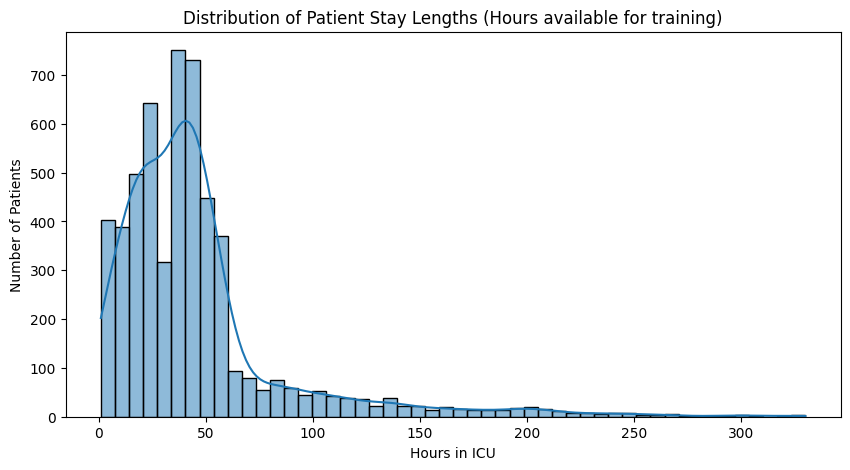

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check Class Distribution (Hour-Level)
counts = df_task['target'].value_counts()
percent = df_task['target'].value_counts(normalize=True) * 100

print("--- Hour-Level Target Distribution ---")
print(f"Healthy Hours (0): {counts[0]} ({percent[0]:.2f}%)")
print(f"Pre-Sepsis Hours (1): {counts[1]} ({percent[1]:.2f}%)")
print("-" * 40)

# 2. Verify the '6-Hour Window' for a Sepsis Patient
# Let's pick one sepsis patient and see if their last 6 hours are now '1'
sample_sepsis_id = sepsis_pids[0]
sample_patient = df_task[df_task['Patient_ID'] == sample_sepsis_id].sort_values('ICULOS')

print(f"Verification for Sepsis Patient {sample_sepsis_id}:")
print(f"Total hours remaining before onset: {len(sample_patient)}")
print("Last 8 rows of their trajectory (Target should be 1 for the final 6):")
print(sample_patient[['ICULOS', 'SepsisLabel', 'target']].tail(8))
print("-" * 40)

# 3. Verify a Non-Sepsis Patient
sample_non_sepsis_id = sampled_non_sepsis_pids[0]
sample_healthy = df_task[df_task['Patient_ID'] == sample_non_sepsis_id]

print(f"Verification for Non-Sepsis Patient {sample_non_sepsis_id}:")
print(f"Total target sum (Should be 0): {sample_healthy['target'].sum()}")
print("-" * 40)

# 4. Visualize Stay Lengths
plt.figure(figsize=(10, 5))
sns.histplot(df_task.groupby('Patient_ID').size(), bins=50, kde=True)
plt.title("Distribution of Patient Stay Lengths (Hours available for training)")
plt.xlabel("Hours in ICU")
plt.ylabel("Number of Patients")
plt.show()